

SOURCE:
- https://www.youtube.com/watch?v=TWU2ZNrsTtk&list=PLNohRKRAHaszuDbT6oSNhD91kpqI18G7d&index=5

1. Load thư viện và data

In [148]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans  #performing k-means clustering
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import warnings
warnings.filterwarnings('ignore')


In [149]:
from sklearn.datasets import load_iris
iris_data = load_iris()

2. EDA

In [150]:
print(iris_data.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [171]:
df = pd.DataFrame(iris_data.data)
df.columns = iris_data.feature_names
df['species'] = iris_data.target
df['species'] = df['species'].map(lambda x: iris_data.target_names[x])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [152]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [153]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


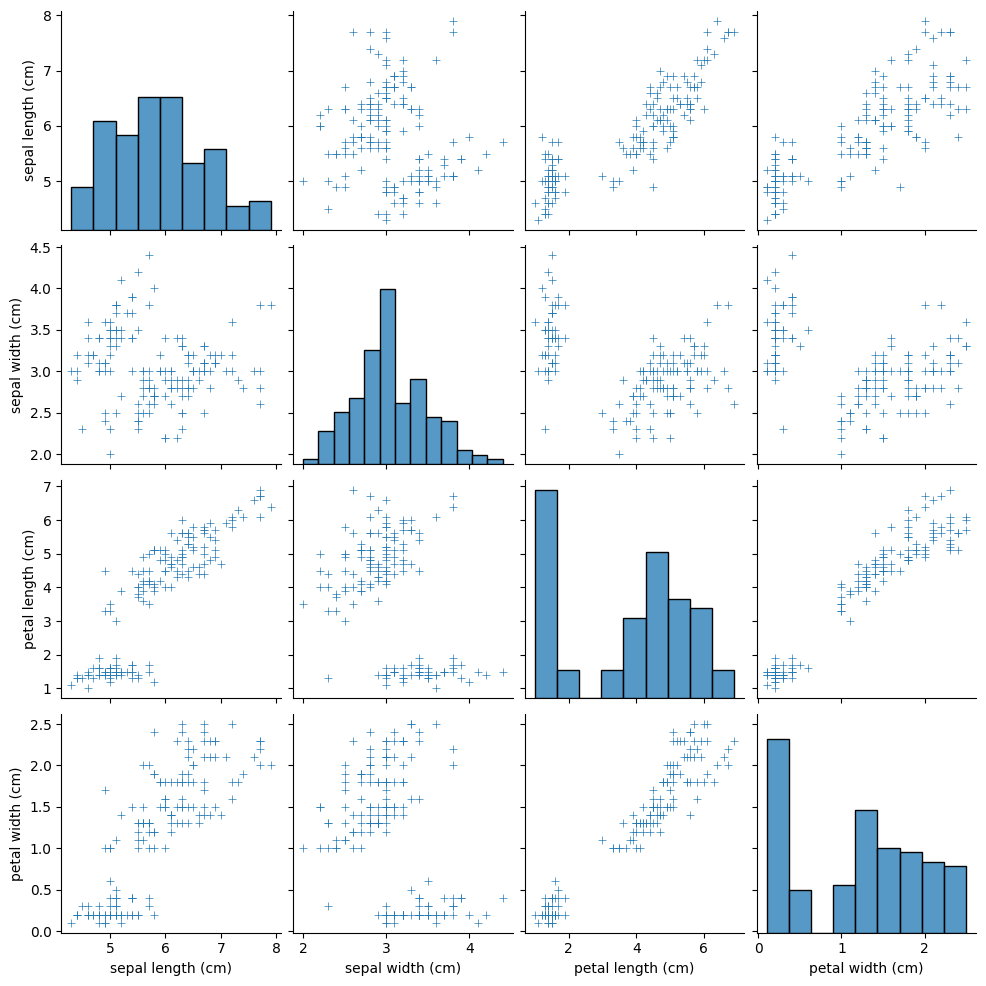

In [154]:
sns.pairplot(df, markers='+')
plt.show()

<Axes: >

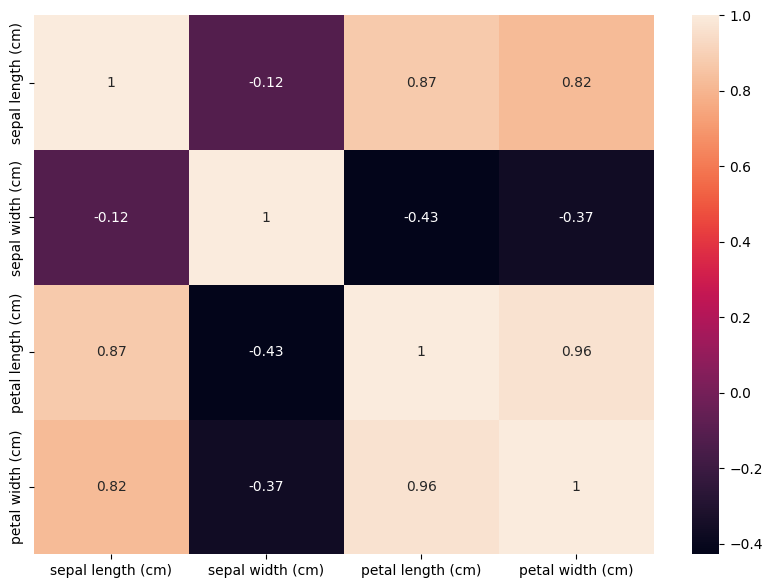

In [155]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(), annot=True) # sns: seaborn library for visualizing

The heatmap shows that petal length and petal width are highly correlated (shown through the skin-tone color).  

In other words, in the 4 features, there is a high chance that if petal length change, petal width is also likely to change.

Aside from heatamp, we can also use other visualization to look into the underlying problem, for example scatter plot.

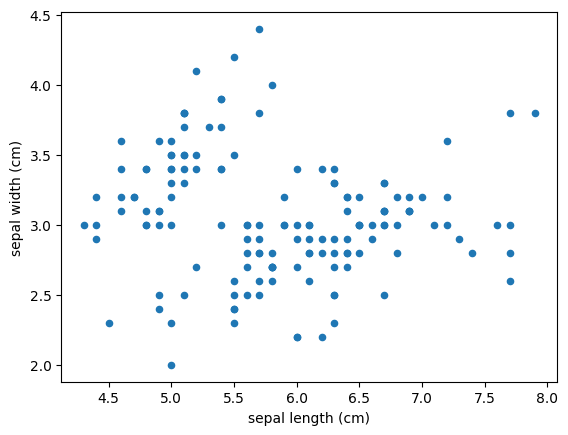

In [156]:
df.plot(kind ='scatter', x= "sepal length (cm)", y= "sepal width (cm)")
plt.show ()

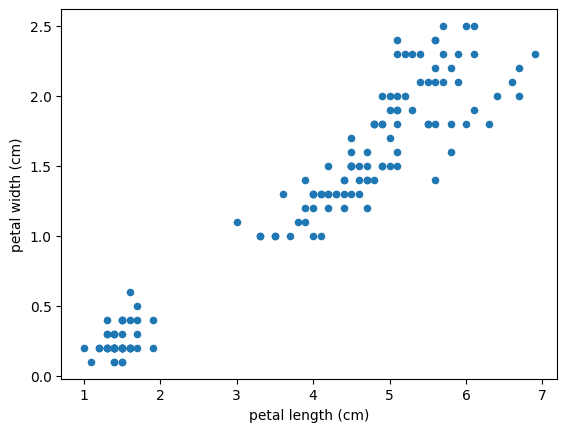

In [157]:
df.plot(kind ='scatter', x= "petal length (cm)", y= "petal width (cm)")
plt.show ()

The 2 picture illustrate the differences between petal and sepal.
- Sepal length and width are scatter, therefore as one changes, the other doesn't change as much -> no strong correlation.
- Petal, on the other hand, is clustered, indicating that if the petal length change, the width is likely to change in the same amount. Resulting in a positive correlated relationship.

3. Data Preprocessing

In [158]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(df)

#KMeans dựa trên khoảng cách Euclidean, dẫn đến các feature lớn có thể ảnh hưởng mạnh đến phân cụm
# -> tiền xử lý để sau so sánh cùng Elbow và Silhouette Score.

## 4. Tìm số lớp tối ưu

- random_state: quy định cách tạo số ngẫu nhiên để các lần chạy sau sẽ được giữ nguyên giá trị.

- n_init: quy định K-Means thử khởi tạo bao nhiêu lần để tìm ra kết quả phân cụm tốt hơn.

In [159]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42# đây là setting tốt cho dataset, với các project khác cần so sánh với r_123 và r_0 để so sánh và chọn.
)

### 1. Elbow Method

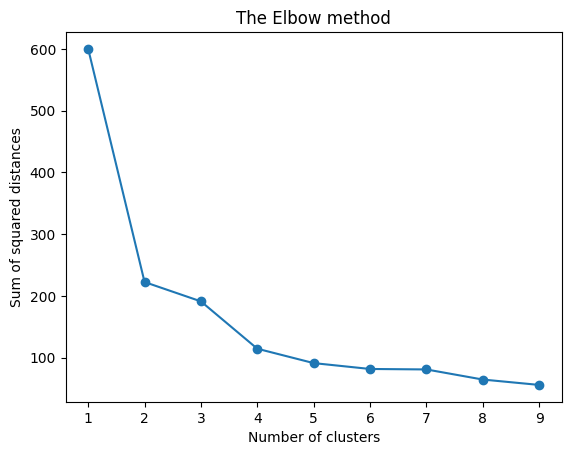

In [160]:
wss = []
for i in range (1,10):
  kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
  kmeans.fit (X)
  wss.append(kmeans.inertia_)

plt.plot(range(1,10),wss, marker="o")
plt.title('The Elbow method')
plt.xlabel('Number of clusters')
plt.ylabel('Sum of squared distances')
plt.show()

For clusters: 9, Silhouette Score: 0.3424


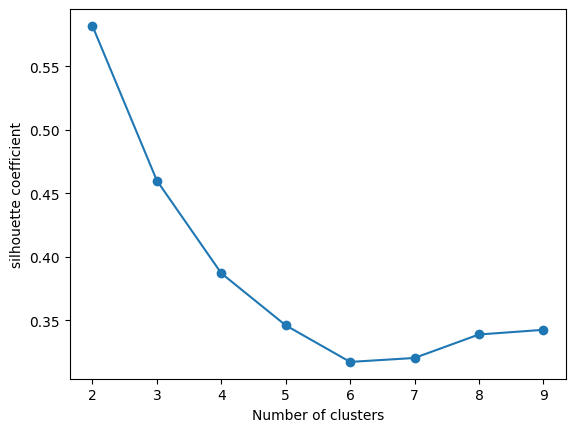

In [161]:
silhouette_coeff = []
for i in range (2,10):
  kmeans = KMeans(
        n_clusters=i,
        init="k-means++",
        n_init=10,
        random_state=42
    )
  labels = kmeans.fit_predict(X)
  score = silhouette_score(X, labels)
  silhouette_coeff.append(score)

print(
     f"For clusters: {i}, "
     f"Silhouette Score: {score:.4f}"
    )

plt.plot(range(2,10),silhouette_coeff, marker="o")
plt.xlabel('Number of clusters')
plt.ylabel('silhouette coefficient')
plt.show()

<Figure size 1000x500 with 0 Axes>

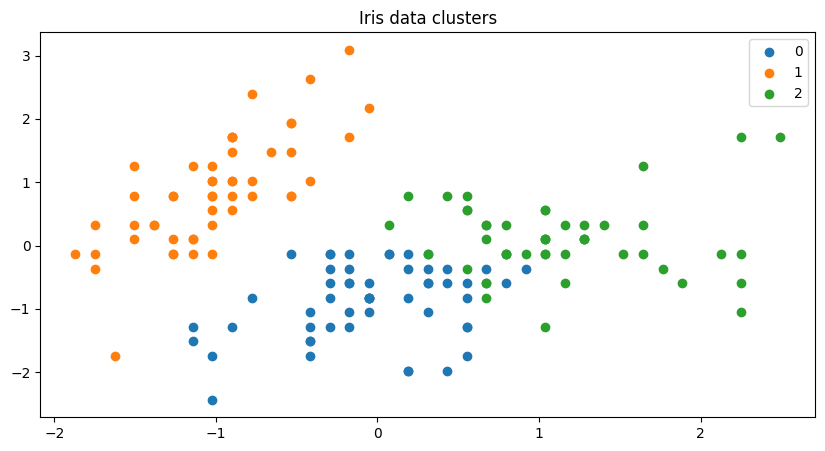

In [162]:
#vẼ BIỂU ĐỒ KMEANS
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
    )
Y = kmeans.fit_predict(X)
unique_labels = np.unique(Y)
plt.figure(figsize=(10,5))
plt.figure(figsize=(10,5))
for i in unique_labels:
  plt.scatter(X[Y==i, 0], X[Y==i, 1], label=i)
plt.title("Iris data clusters")
plt.legend()
plt.show()

### 2. GMM - Gaussian Mixture Model
Giả định dữ liệu được tạo ra từ nhiều phân phối Gaussian.

In [163]:
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(
    n_components=3, #gán mô hình hóa dữ liệu bằng 3 thành phần Gaussian
    covariance_type="full",
    random_state=42
)
gmm_labels = gmm.fit_predict(X)

print("Number of clusters:", len(np.unique(gmm_labels)))
print("Cluster labels:", np.unique(gmm_labels))

Number of clusters: 3
Cluster labels: [0 1 2]


In [164]:
gmm_probs = gmm.predict_proba(X)

print(gmm_probs[:5])

[[2.74503381e-011 1.00000000e+000 0.00000000e+000]
 [1.16033052e-007 9.99999884e-001 0.00000000e+000]
 [9.72921434e-009 9.99999990e-001 5.88168010e-278]
 [2.02193473e-007 9.99999798e-001 3.33173699e-141]
 [9.67775891e-012 1.00000000e+000 0.00000000e+000]]


In [165]:
#1. Xem nhãn cụm
print(gmm_labels[:10])

#2. Xem xác suất
print(gmm_probs[:10])

#3. Xem xác suất 1 điểm cụ thể
print(gmm_probs[0])

[1 1 1 1 1 1 1 1 2 1]
[[2.74503381e-011 1.00000000e+000 0.00000000e+000]
 [1.16033052e-007 9.99999884e-001 0.00000000e+000]
 [9.72921434e-009 9.99999990e-001 5.88168010e-278]
 [2.02193473e-007 9.99999798e-001 3.33173699e-141]
 [9.67775891e-012 1.00000000e+000 0.00000000e+000]
 [1.14329874e-012 1.00000000e+000 0.00000000e+000]
 [5.99406192e-009 9.99999994e-001 4.07722398e-049]
 [4.78561583e-010 1.00000000e+000 0.00000000e+000]
 [4.58916917e-007 1.19519047e-001 8.80480494e-001]
 [9.28895274e-008 9.99999907e-001 0.00000000e+000]]
[2.74503381e-11 1.00000000e+00 0.00000000e+00]


- Chọn trước 3 thành phần Gaussian để mô hình hóa dữ liệu, trong đó mỗi thành phần có ma trận hiệp phương sai riêng (giúp mô hình biểu diễn các cụm có hình dạng và hướng khác nhau) và random sate được cố định để tái lập kết quả.

- Kết quả predict_proba() cho thấy xác suất thuộc cụm 1 của 5 quan sát đầu đều gần 100%.

-> Để đánh giá chất lượng phân cụm và lựa chọn số thành phần phù hợp, có thể kết hợp Sillhoutte Score, AIC, BIC và trực quan hóa kết quả.


### 3. DBSCAN - Density-Based Spatial Clustering of Applications with Noise
Xác định cụm dựa trên mật độ các điểm dữ liệu.

Trong DBSCAN, khác với KMenas và GMM sẽ gán số cụm trước, thuật toán DBSCAN sẽ tìm những vùng có mật độ tối điểm đủ cao để hình thành cụm. -> cần thực hiện thử nghiệm các cụm để có điểm tối ưu so với dataset.

In [166]:
from sklearn.cluster import DBSCAN
import numpy as np

eps_values = [0.3, 0.5, 0.8, 1.0, 1.2]

for eps in eps_values:
    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan.fit_predict(X)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_points = np.sum(labels == -1)

    print(f"eps={eps}")
    print("Number of clusters:", n_clusters)
    print("Number of noise points:", noise_points)
    print("-" * 30)

eps=0.3
Number of clusters: 3
Number of noise points: 120
------------------------------
eps=0.5
Number of clusters: 2
Number of noise points: 34
------------------------------
eps=0.8
Number of clusters: 2
Number of noise points: 4
------------------------------
eps=1.0
Number of clusters: 2
Number of noise points: 3
------------------------------
eps=1.2
Number of clusters: 2
Number of noise points: 1
------------------------------


EPS tăng từ 0.3 lên 1.2 -> số điểm noise giảm từ 120 xuống 1. Tuy nhiên, số cụm cũng giảm từ 3 -> 2.
-> cần thực hiện Silhouette Score và trực quan hóa để đánh giá chất lượng phân cụm.     

In [167]:
eps_values = [0.3, 0.5, 0.8, 1.0, 1.2]

results = []

for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=5)
    labels = model.fit_predict(X)

    # Loại noise khỏi phần tính metric
    mask = labels != -1
    X_eval = X[mask]
    labels_eval = labels[mask]

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    if 2 <= len(np.unique(labels_eval)) < len(labels_eval):
        silhouette = silhouette_score(X_eval, labels_eval)
        dbi = davies_bouldin_score(X_eval, labels_eval)
        ch = calinski_harabasz_score(X_eval, labels_eval)
    else:
        silhouette = np.nan
        dbi = np.nan
        ch = np.nan

    results.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "noise_points": n_noise,
        "silhouette": silhouette,
        "DBI": dbi,
        "CH": ch
    })

dbscan_results = pd.DataFrame(results)
dbscan_results

,eps,n_clusters,noise_points,silhouette,DBI,CH
0,0.3,3,120,0.630176,0.459371,179.155740
1,0.5,2,34,0.655889,0.494216,343.968085
2,0.8,2,4,0.597941,0.568802,277.650960
3,1.0,2,3,0.595186,0.571357,273.197572
4,1.2,2,1,0.586763,0.579959,256.850630


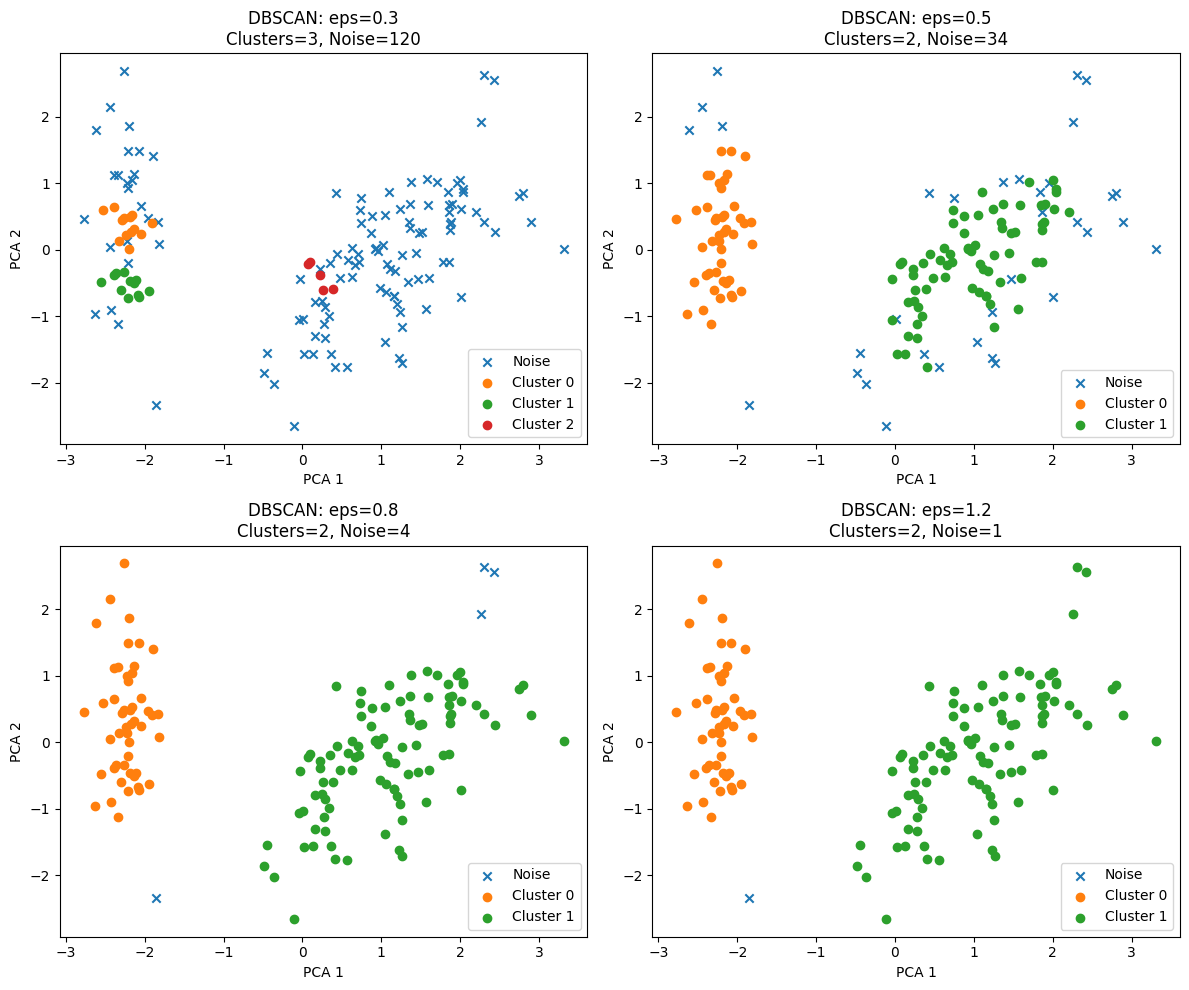

In [168]:
eps_values = [0.3, 0.5, 0.8, 1.2]

# Chiếu dữ liệu đã scale xuống 2 chiều để trực quan hóa
X_pca = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, eps in zip(axes, eps_values):
    model = DBSCAN(eps=eps, min_samples=5)
    labels = model.fit_predict(X)

    # Vẽ từng cụm; label -1 là noise
    for label in sorted(set(labels)):
        mask = labels == label

        if label == -1:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                label="Noise",
                marker="x"
            )
        else:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                label=f"Cluster {label}"
            )

    n_clusters = len(set(labels) - {-1})
    n_noise = sum(labels == -1)

    ax.set_title(
        f"DBSCAN: eps={eps}\n"
        f"Clusters={n_clusters}, Noise={n_noise}"
    )
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend()

plt.tight_layout()
plt.show()

Qua biểu đồ, có thể thấy các metrics (có loại bỏ noise points):
- eps 0.3 không hình thành cụm rõ ràng và quá nhiều noise.

- khi eps tăng lên 0.5, các cụm giảm từ 3 xuống 2, hình thành rõ hơn và noise giảm đáng kể từ 120 -> 34.  Điểm Silhoutte có điểm cao nhất, cho thấy các cụm được đánh giá là khá tách biệt và chặt chẽ.

- tại eps 0.8, số cụm chỉ còn 2, với mật dộ tăng và nhóm dữ liệu chỉnh được phân hóa rõ ràng. Ngoài ra, noise lúc này chỉ còn 4 điểm và cụm có xu hướng ổn định hơn so với khi tăng eps lên 1.0 hay 1.2

=> Dù eps=0.5 có Silhoutte và CH cao nhất trong các cấu hình, eps=0.8 lại có ít noise đáng kể (xấp xỉ 80%) -> trong dự án này sẽ ưu tiên chọn eps 0.8 để giữ lại nhiều quan sát hơnmà không làm giảm các metric quá nhiều.

### 5. So sánh KMeans, GMM, DSBCAN

### Nhận xét:
Ba thuật toán phân cụm được sử dụng trong bài, bao gồm: KMeans, GMM, và DBSCAN.

Trong đó, KMeans và GMM được cấu hình để tạo ra 3 cụm, trong khi DBSCAN xác định được 2 cụm với eps=0.8 và min_samples=5.

KMeans đạt điểm Silhoutte tại 0.4599, DBI bằng 0.8335 và CH 241.90. GMM đạt điểm Silhouette cao hơn một chút tại 0.4751, nhưng DBI cao hơn (0.8867) và CH thấp hơn (141.23).

DBSCAN đạt Silhouette tại 0.5979, DBI 0.5688, CH 277.65 và xác định 4 quan sát là noise.



In [169]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)
dbscan_labels = dbscan.fit_predict(X)
def calculate_metrics(X, labels, exclude_noise=False):
    noise_points = np.sum(labels == -1)

    if exclude_noise:
        mask = labels != -1
        X = X[mask]
        labels = labels[mask]
    n_clusters = len(set(labels) - {-1})

    # Các chỉ số cần ít nhất 2 cụm
    if n_clusters < 2 or n_clusters >= len(labels):
        return {
            "n_clusters": n_clusters,
            "noise_points": noise_points,
            "silhouette": None,
            "DBI": None,
            "CH": None
        }

    return {
        "n_clusters": n_clusters,
        "noise_points": noise_points,
        "silhouette": silhouette_score(X, labels),
        "DBI": davies_bouldin_score(X, labels),
        "CH": calinski_harabasz_score(X, labels)
    }

kmeans_metrics = calculate_metrics(X, Y)
gmm_metrics = calculate_metrics(X, gmm_labels)
dbscan_metrics = calculate_metrics(
    X, dbscan_labels, exclude_noise=True
)

comparison = pd.DataFrame([
    {"Model": "KMeans", **kmeans_metrics},
    {"Model": "GMM", **gmm_metrics},
    {"Model": "DBSCAN (eps=0.8)", **dbscan_metrics}
])

comparison

,Model,n_clusters,noise_points,silhouette,DBI,CH
0,KMeans,3,0,0.459948,0.833595,241.904402
1,GMM,3,0,0.475143,0.886715,141.231476
2,DBSCAN (eps=0.8),2,4,0.597941,0.568802,277.650960


NHÁP
- Vẽ biểu đồ phụ

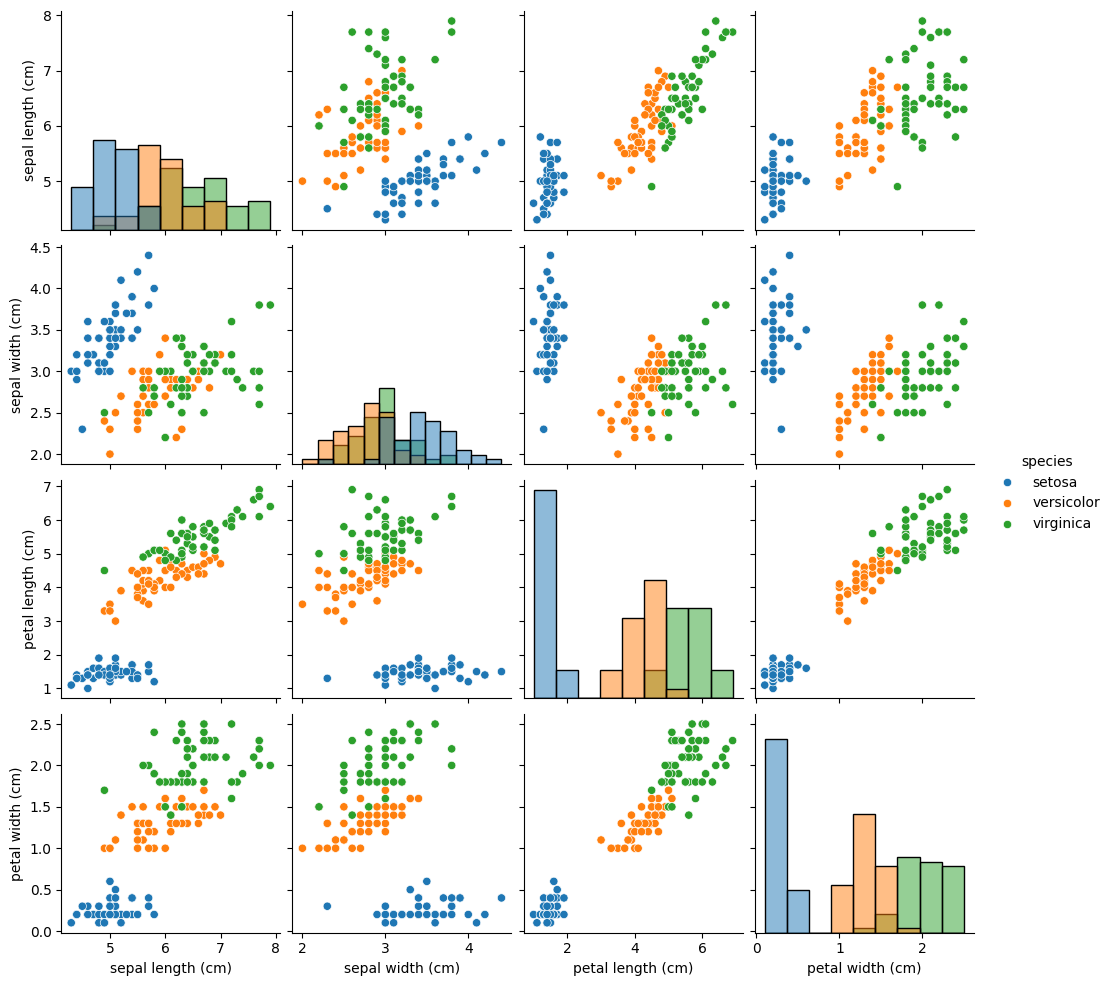

In [173]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    df,
    vars=iris_data.feature_names,
    hue="species",
    diag_kind="hist"
)

plt.show()

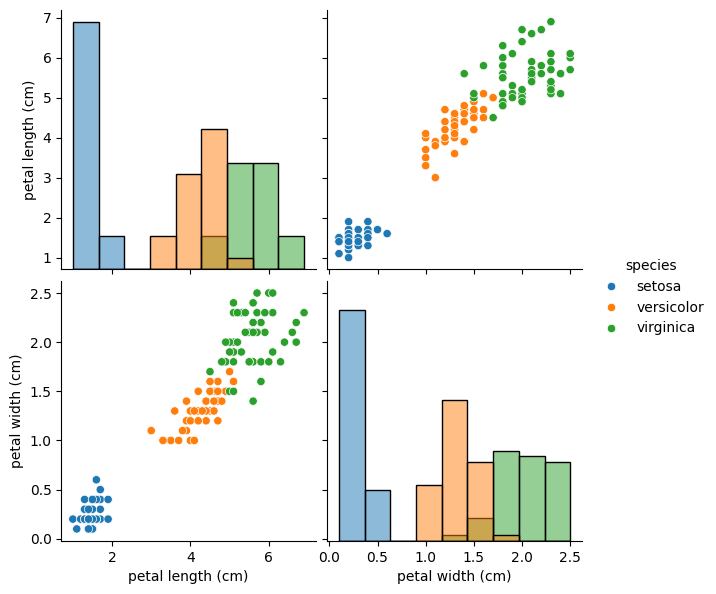

In [174]:
sns.pairplot(
    df,
    vars=["petal length (cm)", "petal width (cm)"],
    hue="species",
    diag_kind="hist",
    height=3
)

plt.show()


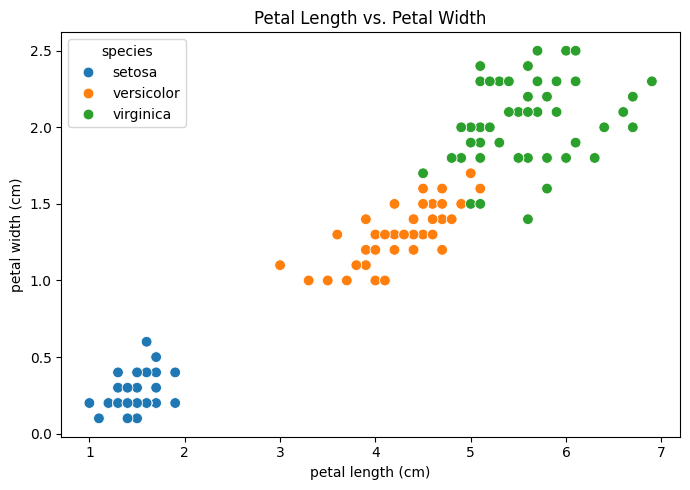

In [175]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=60
)

plt.title("Petal Length vs. Petal Width")
plt.tight_layout()
plt.show()
